In [9]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil
import tarfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42

PROJECT_DIR = Path("/content/drive/MyDrive/Manufacturing_Defects")
ARCHIVE_DIR = PROJECT_DIR / "archives"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Images will be extracted to the Colab runtime for faster reading.
DATA_DIR = Path("/content/mvtec_ad")

for folder in [ARCHIVE_DIR, OUTPUT_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CATEGORIES = ["bottle", "cable"]

print("Archives found:")
for path in sorted(ARCHIVE_DIR.iterdir()):
    print(path.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archives found:
mvtec_anomaly_detection.tar.xz


In [7]:
from pathlib import Path

archive = Path(
    "/content/drive/MyDrive/Manufacturing_Defects/archives/"
    "mvtec_anomaly_detection.tar.xz"
)

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Folder exists:", archive.parent.exists())
print("Dataset file exists:", archive.exists())

if archive.parent.exists():
    print("Folder contents:", [p.name for p in archive.parent.iterdir()])

Drive mounted: True
Folder exists: True
Dataset file exists: True
Folder contents: ['mvtec_anomaly_detection.tar.xz']


In [10]:
archives = sorted(ARCHIVE_DIR.glob("*.tar.xz"))

if not archives:
    raise FileNotFoundError(
        f"No .tar.xz archives found in {ARCHIVE_DIR}. "
        "Upload the dataset archives to this folder first."
    )

for archive_path in archives:
    local_archive = Path("/content") / archive_path.name
    shutil.copy2(archive_path, local_archive)

    extracted = 0

    with tarfile.open(local_archive, mode="r:xz") as archive:
        for member in tqdm(archive, desc=f"Extracting {archive_path.name}"):
            if not member.isfile():
                continue

            parts = Path(member.name).parts

            # Locate the category even if the archive has an outer folder.
            category_index = next(
                (i for i, part in enumerate(parts) if part in CATEGORIES),
                None
            )

            if category_index is None:
                continue

            relative_path = Path(*parts[category_index:])
            destination = DATA_DIR / relative_path

            # Keep every extracted file inside DATA_DIR.
            if not destination.resolve().is_relative_to(DATA_DIR.resolve()):
                raise ValueError(f"Unsafe archive path: {member.name}")

            destination.parent.mkdir(parents=True, exist_ok=True)

            with archive.extractfile(member) as source:
                with destination.open("wb") as target:
                    shutil.copyfileobj(source, target)

            extracted += 1

    local_archive.unlink()
    print(f"{archive_path.name}: extracted {extracted} files")

for category in CATEGORIES:
    for split in ["train", "test", "ground_truth"]:
        folder = DATA_DIR / category / split
        assert folder.is_dir(), f"Missing expected folder: {folder}"

print("Dataset extracted successfully.")

Extracting mvtec_anomaly_detection.tar.xz: 0it [00:00, ?it/s]

mvtec_anomaly_detection.tar.xz: extracted 825 files
Dataset extracted successfully.


In [11]:
rows = []
bad_files = []

for category in CATEGORIES:
    category_dir = DATA_DIR / category

    for split in ["train", "test"]:
        for image_path in sorted((category_dir / split).glob("*/*.png")):
            defect_type = image_path.parent.name
            is_anomaly = defect_type != "good"

            mask_path = (
                category_dir
                / "ground_truth"
                / defect_type
                / f"{image_path.stem}_mask.png"
                if is_anomaly else None
            )

            try:
                with Image.open(image_path) as image:
                    image.load()  # Decode the file to catch unreadable images.
                    width, height = image.size
                    mode = image.mode
            except Exception as error:
                bad_files.append((str(image_path), str(error)))
                continue

            rows.append({
                "category": category,
                "split": split,
                "defect_type": defect_type,
                "label": "defective" if is_anomaly else "normal",
                "is_anomaly": int(is_anomaly),
                "width": width,
                "height": height,
                "mode": mode,
                "relative_path": str(image_path.relative_to(DATA_DIR)),
                "image_path": str(image_path),
                "mask_path": str(mask_path) if mask_path else None,
                "mask_exists": mask_path.exists() if mask_path else False,
            })

df = pd.DataFrame(rows)

assert not df.empty, "No images found. Check the extracted folders."

print(f"Readable product images: {len(df):,}")
print(f"Unreadable images: {len(bad_files)}")

display(df.head())

if bad_files:
    display(pd.DataFrame(bad_files, columns=["path", "error"]))

assert df.loc[df["split"] == "train", "is_anomaly"].eq(0).all(), (
    "Unexpected defective images in training."
)

missing_masks = df[
    (df["is_anomaly"] == 1) & (~df["mask_exists"])
]

print(f"Defective images missing masks: {len(missing_masks)}")

Readable product images: 666
Unreadable images: 0


,category,split,defect_type,label,is_anomaly,width,height,mode,relative_path,image_path,mask_path,mask_exists
0,bottle,train,good,normal,0,900,900,RGB,bottle/train/good/000.png,/content/mvtec_ad/bottle/train/good/000.png,None,False
1,bottle,train,good,normal,0,900,900,RGB,bottle/train/good/001.png,/content/mvtec_ad/bottle/train/good/001.png,None,False
2,bottle,train,good,normal,0,900,900,RGB,bottle/train/good/002.png,/content/mvtec_ad/bottle/train/good/002.png,None,False
3,bottle,train,good,normal,0,900,900,RGB,bottle/train/good/003.png,/content/mvtec_ad/bottle/train/good/003.png,None,False
4,bottle,train,good,normal,0,900,900,RGB,bottle/train/good/004.png,/content/mvtec_ad/bottle/train/good/004.png,None,False


Defective images missing masks: 0


label           normal  defective
category split                   
bottle   test       20         63
         train     209          0
cable    test       58         92
         train     224          0

,category,defect_type,image_count
0,bottle,broken_large,20
1,bottle,broken_small,22
2,bottle,contamination,21
3,bottle,good,20
4,cable,bent_wire,13
5,cable,cable_swap,12
6,cable,combined,11
7,cable,cut_inner_insulation,14
8,cable,cut_outer_insulation,10
9,cable,good,58


,category,width,height,mode,image_count
0,bottle,900,900,RGB,292
1,cable,1024,1024,RGB,374


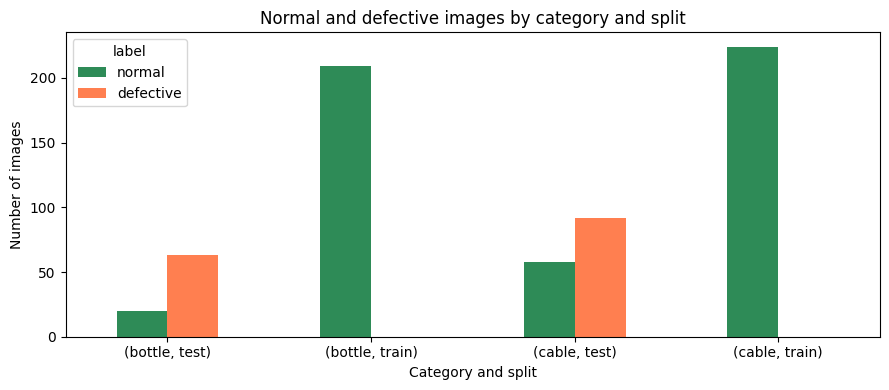

In [12]:
# Counts by product, split, and normal/defective status
counts = (
    df.groupby(["category", "split", "label"])
      .size()
      .unstack("label", fill_value=0)
      .reindex(columns=["normal", "defective"], fill_value=0)
)

display(counts)

# Counts for individual defect types
defect_counts = (
    df[df["split"] == "test"]
    .groupby(["category", "defect_type"])
    .size()
    .rename("image_count")
    .reset_index()
)

display(defect_counts)

# Original image dimensions and colour modes
dimensions = (
    df.groupby(["category", "width", "height", "mode"])
    .size()
    .rename("image_count")
    .reset_index()
)

display(dimensions)

ax = counts.plot(
    kind="bar",
    figsize=(9, 4),
    color=["seagreen", "coral"],
    rot=0
)

ax.set_title("Normal and defective images by category and split")
ax.set_xlabel("Category and split")
ax.set_ylabel("Number of images")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "image_counts.png", dpi=160)
plt.show()

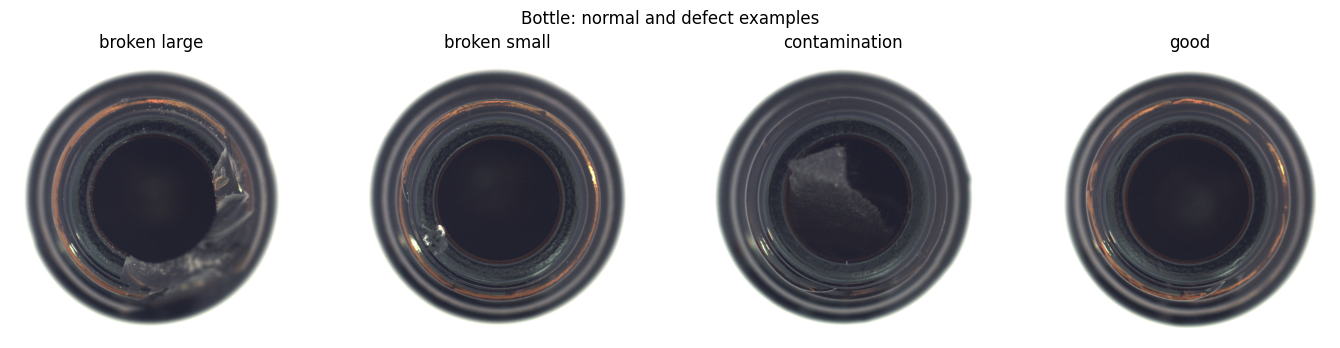

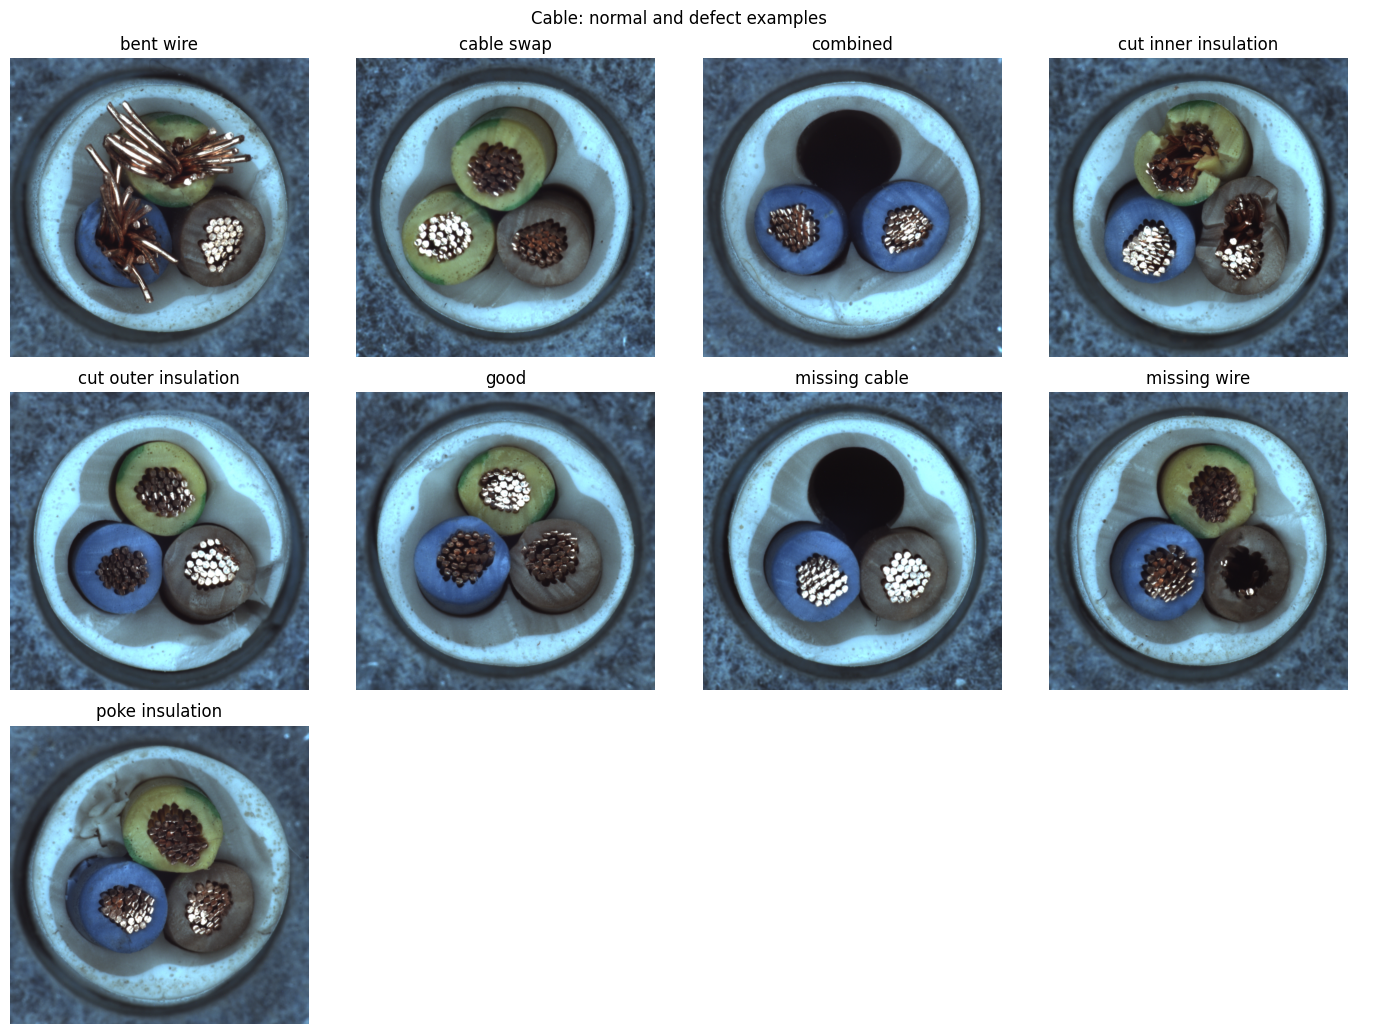

In [13]:
for category in CATEGORIES:
    subset = df[
        (df["category"] == category) &
        (df["split"] == "test")
    ]

    defect_types = sorted(subset["defect_type"].unique())
    ncols = 4
    nrows = int(np.ceil(len(defect_types) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(14, 3.5 * nrows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, defect_type in zip(axes.flat, defect_types):
        row = subset[
            subset["defect_type"] == defect_type
        ].sample(1, random_state=SEED).iloc[0]

        with Image.open(row["image_path"]) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(defect_type.replace("_", " "))

    fig.suptitle(f"{category.title()}: normal and defect examples")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{category}_examples.png", dpi=160)
    plt.show()

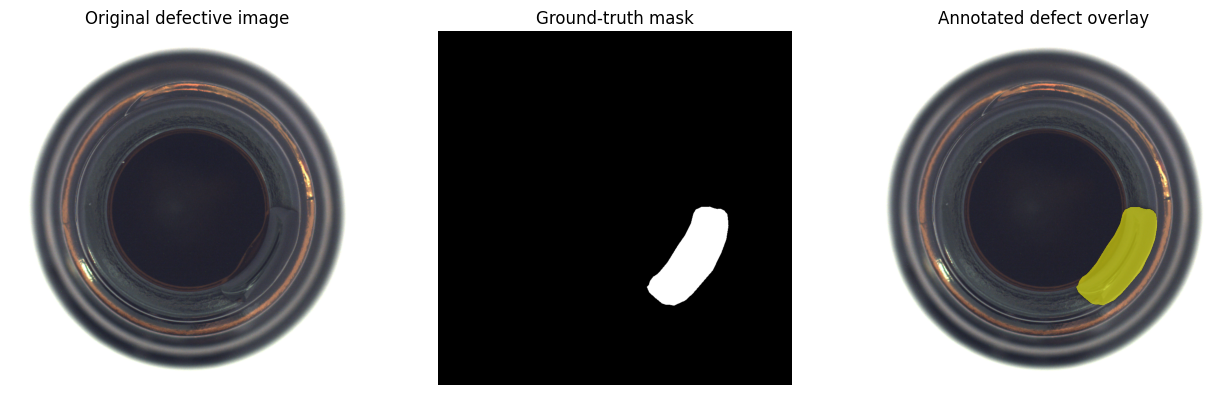

Defect type: contamination
Defect covers 3.33% of image pixels.


In [14]:
row = df[
    (df["category"] == "bottle") &
    (df["is_anomaly"] == 1) &
    (df["mask_exists"])
].sample(1, random_state=SEED).iloc[0]

with Image.open(row["image_path"]) as image:
    image_array = np.array(image.convert("RGB"))

with Image.open(row["mask_path"]) as mask:
    mask_array = np.array(mask.convert("L")) > 0

assert mask_array.shape == image_array.shape[:2], (
    "Image and mask dimensions do not match."
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(image_array)
axes[0].set_title("Original defective image")

axes[1].imshow(mask_array, cmap="gray")
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image_array)
axes[2].imshow(
    np.ma.masked_where(~mask_array, mask_array.astype(float)),
    cmap="autumn",
    alpha=0.55,
    vmin=0,
    vmax=1
)
axes[2].set_title("Annotated defect overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "defect_mask_example.png", dpi=160)
plt.show()

print("Defect type:", row["defect_type"])
print(f"Defect covers {mask_array.mean() * 100:.2f}% of image pixels.")

In [15]:
df.to_csv(OUTPUT_DIR / "image_metadata.csv", index=False)
counts.to_csv(OUTPUT_DIR / "image_counts.csv")
defect_counts.to_csv(OUTPUT_DIR / "defect_type_counts.csv", index=False)
dimensions.to_csv(OUTPUT_DIR / "image_dimensions.csv", index=False)

print("EDA outputs saved to:", OUTPUT_DIR)

EDA outputs saved to: /content/drive/MyDrive/Manufacturing_Defects/outputs


In [16]:
# Training and testing counts for each category
split_counts = (
    df.groupby(["category", "split"])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=["train", "test"], fill_value=0)
)

print("IMAGE COUNTS")
display(split_counts)

# Only defective test images — exclude "good"
defect_counts = (
    df[
        (df["split"] == "test") &
        (df["is_anomaly"] == 1)
    ]
    .groupby(["category", "defect_type"])
    .size()
    .rename("count")
    .reset_index()
)

print("\nDEFECT COUNTS")
display(defect_counts)

# Include all tied most/least common defect types
frequency_notes = []

for category in CATEGORIES:
    subset = defect_counts[defect_counts["category"] == category]

    if subset.empty:
        frequency_notes.append(
            f"- **{category.title()}:** no defective test images found."
        )
        continue

    highest = subset["count"].max()
    lowest = subset["count"].min()

    most_common = ", ".join(
        subset.loc[subset["count"] == highest, "defect_type"]
    )
    least_common = ", ".join(
        subset.loc[subset["count"] == lowest, "defect_type"]
    )

    frequency_notes.append(
        f"- **{category.title()}:** most common: "
        f"{most_common} ({highest} images each); "
        f"least common: {least_common} ({lowest} images each)."
    )

print("\n".join(frequency_notes))

IMAGE COUNTS


split,train,test
category,,
bottle,209,83
cable,224,150



DEFECT COUNTS


,category,defect_type,count
0,bottle,broken_large,20
1,bottle,broken_small,22
2,bottle,contamination,21
3,cable,bent_wire,13
4,cable,cable_swap,12
5,cable,combined,11
6,cable,cut_inner_insulation,14
7,cable,cut_outer_insulation,10
8,cable,missing_cable,12
9,cable,missing_wire,10


- **Bottle:** most common: broken_small (22 images each); least common: broken_large (20 images each).
- **Cable:** most common: cut_inner_insulation (14 images each); least common: cut_outer_insulation, missing_wire, poke_insulation (10 images each).


In [17]:
missing_images = [
    path for path in df["image_path"]
    if not Path(path).is_file()
]

mask_issues = []
mask_area_rows = []

defective_images = df[df["is_anomaly"] == 1]

for row in tqdm(
    defective_images.itertuples(index=False),
    total=len(defective_images),
    desc="Checking masks"
):
    mask_path = row.mask_path

    if pd.isna(mask_path) or not Path(mask_path).is_file():
        mask_issues.append({
            "image_path": row.image_path,
            "issue": "Missing mask"
        })
        continue

    try:
        with Image.open(mask_path) as mask:
            mask_array = np.array(mask.convert("L")) > 0

        if mask_array.shape != (row.height, row.width):
            mask_issues.append({
                "image_path": row.image_path,
                "issue": "Mask dimensions do not match image"
            })
            continue

        if not mask_array.any():
            mask_issues.append({
                "image_path": row.image_path,
                "issue": "Empty defect mask"
            })
            continue

        mask_area_rows.append({
            "category": row.category,
            "defect_type": row.defect_type,
            "image_path": row.image_path,
            "mask_path": row.mask_path,
            "defect_area_percent": float(mask_array.mean() * 100)
        })

    except Exception as error:
        mask_issues.append({
            "image_path": row.image_path,
            "issue": str(error)
        })

mask_areas = pd.DataFrame(mask_area_rows)

print("Missing indexed images:", len(missing_images))
print("Unreadable images recorded in Step 5:", len(bad_files))
print("Mask issues:", len(mask_issues))

if mask_issues:
    display(pd.DataFrame(mask_issues))

Checking masks:   0%|          | 0/155 [00:00<?, ?it/s]

Missing indexed images: 0
Unreadable images recorded in Step 5: 0
Mask issues: 0


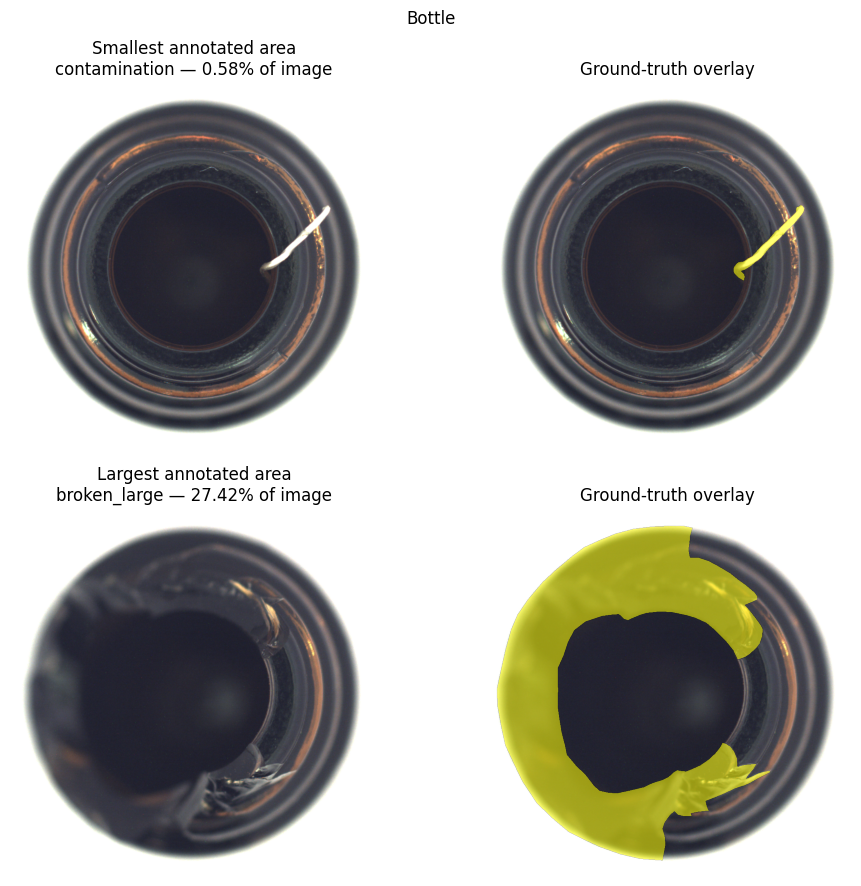

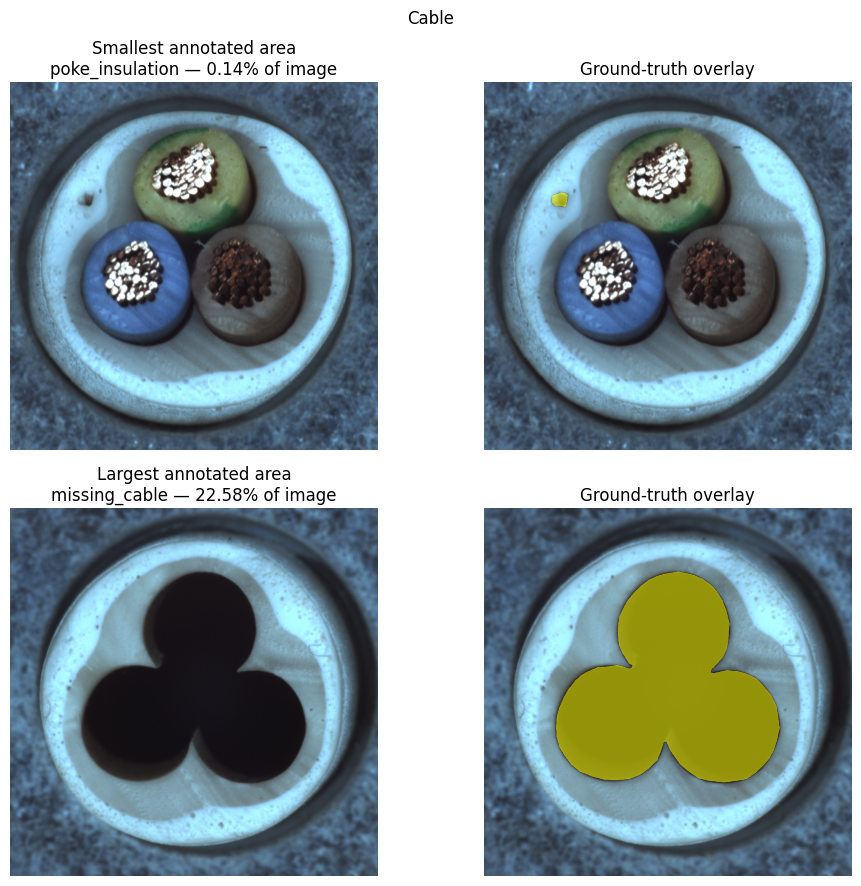

In [18]:
area_notes = []

if mask_areas.empty:
    print("No valid masks available. Resolve the mask issues first.")

else:
    for category in CATEGORIES:
        subset = mask_areas[
            mask_areas["category"] == category
        ]

        if subset.empty:
            continue

        smallest = subset.loc[subset["defect_area_percent"].idxmin()]
        largest = subset.loc[subset["defect_area_percent"].idxmax()]

        fig, axes = plt.subplots(2, 2, figsize=(10, 9))

        for row_index, (label, example) in enumerate([
            ("Smallest annotated area", smallest),
            ("Largest annotated area", largest)
        ]):
            with Image.open(example["image_path"]) as image:
                image_array = np.array(image.convert("RGB"))

            with Image.open(example["mask_path"]) as mask:
                mask_array = np.array(mask.convert("L")) > 0

            axes[row_index, 0].imshow(image_array)
            axes[row_index, 0].set_title(
                f"{label}\n"
                f"{example['defect_type']} — "
                f"{example['defect_area_percent']:.2f}% of image"
            )

            axes[row_index, 1].imshow(image_array)
            axes[row_index, 1].imshow(
                np.ma.masked_where(
                    ~mask_array, mask_array.astype(float)
                ),
                cmap="autumn",
                alpha=0.55,
                vmin=0,
                vmax=1
            )
            axes[row_index, 1].set_title("Ground-truth overlay")

        for ax in axes.flat:
            ax.axis("off")

        fig.suptitle(category.title())
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"{category}_small_large_defects.png",
            dpi=160
        )
        plt.show()

        area_notes.append(
            f"- **{category.title()}:** the smallest annotated example "
            f"is `{smallest['defect_type']}` "
            f"({smallest['defect_area_percent']:.2f}% of image pixels); "
            f"the largest is `{largest['defect_type']}` "
            f"({largest['defect_area_percent']:.2f}%)."
        )

In [19]:
from IPython.display import Markdown

count_notes = []

for category, row in split_counts.iterrows():
    count_notes.append(
        f"- **{category.title()}:** "
        f"{int(row['train'])} training images and "
        f"{int(row['test'])} testing images."
    )

summary = f"""
## Initial exploratory data analysis

### Dataset size
{chr(10).join(count_notes)}

The original training split contains normal products only.
The original test split contains both normal and defective products.

### Defect frequencies
{chr(10).join(frequency_notes)}

### Data-quality checks
- Missing indexed image files: {len(missing_images)}.
- Unreadable images recorded during loading: {len(bad_files)}.
- Missing, unreadable, empty, or incorrectly sized masks: {len(mask_issues)}.

These checks assess the files available locally; they do not independently
verify that the downloaded dataset is complete.

### Examples of defect size
{chr(10).join(area_notes) if area_notes else "No valid defect-area examples were available."}

Defect area measures size, rather than visual obviousness.
Small defects may occupy very few pixels and become harder to identify
after resizing. The original images and mask overlays should therefore
be inspected together.

### Why accuracy alone is insufficient
Overall accuracy combines all correct predictions into one number.
Strong performance on normal products and common defects can therefore
hide poor detection of rare defect types.

For example, a hypothetical model that predicts every image as normal
would achieve 95% accuracy on a dataset containing 95% normal products,
while detecting none of its defects. This is an illustration, not a
description of the class distribution in this dataset.

Evaluation should include image-level AUROC, precision, recall, F1,
a confusion matrix, and recall for each defect type. If localisation
is evaluated, pixel-level or region-level metrics should also be reported.

### Evaluation discipline
The original test split is retained for final evaluation.
Test images, labels, and masks will not be used to fit the model,
select hyperparameters, or choose a decision threshold.
"""

display(Markdown(summary))

(OUTPUT_DIR / "eda_summary.md").write_text(
    summary,
    encoding="utf-8"
)

print("Saved:", OUTPUT_DIR / "eda_summary.md")


## Initial exploratory data analysis

### Dataset size
- **Bottle:** 209 training images and 83 testing images.
- **Cable:** 224 training images and 150 testing images.

The original training split contains normal products only.
The original test split contains both normal and defective products.

### Defect frequencies
- **Bottle:** most common: broken_small (22 images each); least common: broken_large (20 images each).
- **Cable:** most common: cut_inner_insulation (14 images each); least common: cut_outer_insulation, missing_wire, poke_insulation (10 images each).

### Data-quality checks
- Missing indexed image files: 0.
- Unreadable images recorded during loading: 0.
- Missing, unreadable, empty, or incorrectly sized masks: 0.

These checks assess the files available locally; they do not independently
verify that the downloaded dataset is complete.

### Examples of defect size
- **Bottle:** the smallest annotated example is `contamination` (0.58% of image pixels); the largest is `broken_large` (27.42%).
- **Cable:** the smallest annotated example is `poke_insulation` (0.14% of image pixels); the largest is `missing_cable` (22.58%).

Defect area measures size, rather than visual obviousness.
Small defects may occupy very few pixels and become harder to identify
after resizing. The original images and mask overlays should therefore
be inspected together.

### Why accuracy alone is insufficient
Overall accuracy combines all correct predictions into one number.
Strong performance on normal products and common defects can therefore
hide poor detection of rare defect types.

For example, a hypothetical model that predicts every image as normal
would achieve 95% accuracy on a dataset containing 95% normal products,
while detecting none of its defects. This is an illustration, not a
description of the class distribution in this dataset.

Evaluation should include image-level AUROC, precision, recall, F1,
a confusion matrix, and recall for each defect type. If localisation
is evaluated, pixel-level or region-level metrics should also be reported.

### Evaluation discipline
The original test split is retained for final evaluation.
Test images, labels, and masks will not be used to fit the model,
select hyperparameters, or choose a decision threshold.


Saved: /content/drive/MyDrive/Manufacturing_Defects/outputs/eda_summary.md


Initial exploratory data analysis
Dataset size

    Bottle: 209 training images and 83 testing images.
    Cable: 224 training images and 150 testing images.

The original training split contains normal products only. The original test split contains both normal and defective products.
Defect frequencies

    Bottle: most common: broken_small (22 images each); least common: broken_large (20 images each).
    Cable: most common: cut_inner_insulation (14 images each); least common: cut_outer_insulation, missing_wire, poke_insulation (10 images each).

Data-quality checks

    Missing indexed image files: 0.
    Unreadable images recorded during loading: 0.
    Missing, unreadable, empty, or incorrectly sized masks: 0.

These checks assess the files available locally; they do not independently verify that the downloaded dataset is complete.
Examples of defect size

    Bottle: the smallest annotated example is contamination (0.58% of image pixels); the largest is broken_large (27.42%).
    Cable: the smallest annotated example is poke_insulation (0.14% of image pixels); the largest is missing_cable (22.58%).

Defect area measures size, rather than visual obviousness. Small defects may occupy very few pixels and become harder to identify after resizing. The original images and mask overlays should therefore be inspected together.
Why accuracy alone is insufficient

Overall accuracy combines all correct predictions into one number. Strong performance on normal products and common defects can therefore hide poor detection of rare defect types.

For example, a hypothetical model that predicts every image as normal would achieve 95% accuracy on a dataset containing 95% normal products, while detecting none of its defects. This is an illustration, not a description of the class distribution in this dataset.

Evaluation should include image-level AUROC, precision, recall, F1, a confusion matrix, and recall for each defect type. If localisation is evaluated, pixel-level or region-level metrics should also be reported.
Evaluation discipline

The original test split is retained for final evaluation. Test images, labels, and masks will not be used to fit the model, select hyperparameters, or choose a decision threshold.

Saved: /content/drive/MyDrive/Manufacturing_Defects/outputs/eda_summary.md


In [20]:
from sklearn.model_selection import train_test_split

assert df.loc[
    df["split"] == "train", "is_anomaly"
].eq(0).all(), "The training split must contain normal images only."

reference_parts = []
validation_parts = []

for category in CATEGORIES:
    category_train = df[
        (df["category"] == category) &
        (df["split"] == "train")
    ].copy()

    reference_part, validation_part = train_test_split(
        category_train,
        test_size=0.20,
        random_state=SEED,
        shuffle=True
    )

    reference_parts.append(reference_part)
    validation_parts.append(validation_part)

reference_df = pd.concat(reference_parts, ignore_index=True)
validation_df = pd.concat(validation_parts, ignore_index=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

# Verify that no indexed image path occurs in two partitions.
reference_paths = set(reference_df["image_path"])
validation_paths = set(validation_df["image_path"])
test_paths = set(test_df["image_path"])

assert reference_paths.isdisjoint(validation_paths)
assert reference_paths.isdisjoint(test_paths)
assert validation_paths.isdisjoint(test_paths)

partition_counts = pd.DataFrame({
    "normal_reference": reference_df.groupby("category").size(),
    "normal_validation": validation_df.groupby("category").size(),
    "original_test": test_df.groupby("category").size()
}).fillna(0).astype(int)

display(partition_counts)

# Save relative paths so the manifests remain useful after a runtime reset.
for name, frame in [
    ("reference", reference_df),
    ("validation", validation_df),
    ("test", test_df)
]:
    frame[
        ["relative_path", "category", "defect_type", "is_anomaly"]
    ].to_csv(
        OUTPUT_DIR / f"{name}_manifest.csv",
        index=False
    )

print("Partitions saved successfully.")

,normal_reference,normal_validation,original_test
category,,,
bottle,167,42,83
cable,179,45,150


Partitions saved successfully.
